# Probabilistic FDM — Poisson方程式 (Matérnカーネル)

PDE: $-u''(x) = f(x) = \sin(2\pi x)$, $\quad u(0)=u(18)=0$

真の解: $u(x) = \frac{1}{(2\pi)^2}\sin(2\pi x)$

観測モデル: $y = H u + \varepsilon$, $\quad H = -\Delta_h$

観測ノイズ:
\[
\varepsilon \sim \mathcal{N}(0,\, C h^{2\tau} I_{M,N}).
\]

この版では

- $\tau=2$ を固定
- $\sigma_f$ は標準FDM解の RMS から固定
- $C$ は target-grid の標準FDM解 $u_h$ に $2h$ stencil を適用した coarsening defect から推定
- $\ell$ のみ log marginal likelihood でグリッドサーチ

とする。追加の $h/2$ solve は不要。


In [1]:
using Plots
using LinearAlgebra
using SpecialFunctions
using Printf
using Statistics

In [5]:
function solve_fdm(dt)
    x_all = collect(0.0:dt:18.0)
    x_int = x_all[2:end-1]
    n_int = length(x_int)
    A = SymTridiagonal(fill(2.0/dt^2, n_int), fill(-1.0/dt^2, n_int-1))
    f_vec = f_func.(x_int)
    u_int = ldiv!(factorize(A), copy(f_vec))
    return x_all, vcat(0.0, u_int, 0.0)
end

dt = 0.4
x_fdm, u_fdm = solve_fdm(dt)
err = maximum(abs.(u_fdm .- u_exact.(x_fdm)))
println("h=$(dt):  max|u_fdm - u_exact| = $(round(err, sigdigits=4))")



σf_rms  = sqrt(mean(u_fdm.^2))
σf_max = maximum(abs.(u_fdm))

println(σf_rms)
println(σf_max)

# --------------------------------------------------------
# C の coarsening-based calibration
#
# truncation error:
#     D_h u - f = c(x) h^p + higher-order terms
#
# target-grid FDM solution u_h を一段粗い 2h stencil で検査すると
#     D_{2h} u_h - f ≈ (2^p - 1) c(x) h^p
#
# よって
#     c_hat(x) = [D_{2h} u_h - f] / [(2^p - 1) h^p]
#     C_hat    = mean(c_hat(x)^2)
#
# 注意:
# [0,18] と h=0.4 のように interval 数が奇数でも使えるよう、
# 完全な 2h-grid は作らず、u_h 上で ±2 index が存在する
# every-other interior point のみを使用する。
# --------------------------------------------------------
function estimate_C_coarsening(dt; p=2)
    x_h, u_h = solve_fdm(dt)
    n = length(x_h)

    # Julia index i corresponds to x_h[i].
    # Use centers i = 3,5,7,... such that i-2 and i+2 both exist.
    idx = collect(3:2:(n-2))
    if isempty(idx)
        error("Grid is too coarse to estimate C using a 2h stencil.")
    end

    h2 = 2dt
    defect = similar(Float64.(idx))

    for (k, i) in enumerate(idx)
        D2h_u = (-u_h[i-2] + 2u_h[i] - u_h[i+2]) / h2^2
        defect[k] = D2h_u - f_func(x_h[i])
    end

    c_hat = defect ./ ((2.0^p - 1.0) * dt^p)
    C_hat = mean(c_hat .^ 2)

    return C_hat, x_h[idx], c_hat, defect
end


h=0.4:  max|u_fdm - u_exact| = 0.01797
0.030928558807569867
0.04205848896953482


estimate_C_coarsening (generic function with 1 method)

## 1. Matérnカーネル

In [6]:
function matern_kernel(x1, x2; ν=1.5, ℓ=1.0, σf=1.0)
    r = abs(x1 - x2)
    if r == 0
        return σf^2
    end
    z = sqrt(2ν) * r / ℓ
    if ν == 0.5
        return σf^2 * exp(-z)
    elseif ν == 1.5
        return σf^2 * (1 + z) * exp(-z)
    elseif ν == 2.5
        return σf^2 * (1 + z + z^2/3) * exp(-z)
    else
        return σf^2 * (2^(1-ν) / gamma(ν)) * z^ν * besselk(ν, z)
    end
end

function kernel_matrix_matern(X1, X2; ν=1.5, ℓ=1.0, σf=1.0)
    [matern_kernel(x1, x2; ν=ν, ℓ=ℓ, σf=σf) for x1 in X1, x2 in X2]
end

kernel_matrix_matern (generic function with 1 method)

## 2. 問題設定・観測行列 H・log周辺尤度

In [7]:
# --------------------------------------------------------
# 問題設定: -u'' = f, u(0)=u(1)=0
# f(x) = sin(2πx), u_exact(x) = sin(2πx)/(2π)^2
# --------------------------------------------------------
u_exact(x) = sin(2π * x) / (2π)^2
f_func(x)  = sin(2π * x)

# --------------------------------------------------------
# 観測行列 H = -Δ_h (負の有限差分ラプラシアン)
# 行順: [bdry_0, int_1, ..., int_{N-1}, bdry_N]
# 内点行: (-u_{i-1} + 2u_i - u_{i+1}) / h^2  = -Δ_h u_i ≈ -u''_i = f_i
# → Hu = y = (0, f(x_1), ..., f(x_{N-1}), 0) と直接対応
# --------------------------------------------------------
function observation_matrix(n_total, dt)
    n_int = n_total - 2
    H = zeros(n_total, n_total)
    H[1, 1]     = 1.0
    H[end, end] = 1.0
    for i in 1:n_int
        H[i+1, i]   = -1.0 / dt^2   # -Δ_h
        H[i+1, i+1] =  2.0 / dt^2
        H[i+1, i+2] = -1.0 / dt^2
    end
    return H
end

# 観測ベクトル: y = (u(0), f(x_1), ..., f(x_{N-1}), u(1))
make_y_train(x_all) = vcat(0.0, f_func.(x_all[2:end-1]), 0.0)

# --------------------------------------------------------
# log周辺尤度: 観測ノイズ Σ = C * h^{2τ} * diag(0,1,...,1,0)
# --------------------------------------------------------
function log_marginal_matern(
    X_train, y; H, dt, ν, ℓ, σf, C, τ, jitter=1e-10
)
    n_total   = length(X_train)
    noise_var = C * dt^(2τ)
    Σ_diag    = vcat([0.0], fill(noise_var, n_total - 2), [0.0])
    Σ         = Diagonal(Σ_diag)

    K     = kernel_matrix_matern(X_train, X_train; ν=ν, ℓ=ℓ, σf=σf)
    K_obs = H * K * H' + Σ #+ jitter * I

    L       = cholesky(Hermitian(K_obs)).L
    α       = L' \ (L \ y)
    logdetK = 2sum(log.(diag(L)))

    return -0.5 * (y' * α) - 0.5 * logdetK - 0.5 * length(y) * log(2π)
end

log_marginal_matern (generic function with 1 method)

## 3. ハイパーパラメータ選択（$C$ は defect calibration、$\ell$ のみグリッドサーチ）


## Proposed hyperparameter selection for four mesh sizes

For each

\[
h\in\{0.75,0.4,0.2,0.05\},
\]

we use

\[
\sigma_f=\sqrt{\operatorname{mean}(u_h^2)},
\qquad
C=\widehat C_{\rm defect},
\]

and select only \(\ell\) by log marginal likelihood.


In [8]:

# ============================================================
# Proposed hyperparameter selection for four h values
# ============================================================

ν_fixed = 1.5
τ_fixed = 2

dt_list = [0.75, 0.4, 0.2, 0.05]

ell_factors = [0.5, 0.75, 1.0, 1.5, 2.0]


best_params = Dict()
ell_scores  = Dict()

for dt in dt_list

    x_train = collect(0.0:dt:18.0)
    n_train = length(x_train)

    H       = observation_matrix(n_train, dt)
    y_train = make_y_train(x_train)

    _, u_fdm = solve_fdm(dt)

    sigma_f =
        sqrt(mean(u_fdm.^2))

    C_hat, x_C, c_hat, defect =
        estimate_C_coarsening(
            dt;
            p=τ_fixed
        )

    # Length-scale candidates centered around the mesh width h
    ell_grid = dt .* ell_factors

    scores =
        fill(
            -Inf,
            length(ell_grid)
        )

    for (i, ell) in enumerate(ell_grid)

        try
            scores[i] =
                log_marginal_matern(
                    x_train,
                    y_train;
                    H=H,
                    dt=dt,
                    ν=ν_fixed,
                    ℓ=ell,
                    σf=sigma_f,
                    C=C_hat,
                    τ=τ_fixed
                )

        catch err
            @warn "LML failed" dt ell exception=(err, catch_backtrace())
            scores[i] = -Inf
        end
    end

    best_idx = argmax(scores)
    best_ell = ell_grid[best_idx]
    best_lml = scores[best_idx]

    best_params[dt] =
        (
            best_ell,
            sigma_f,
            C_hat,
            best_lml
        )

    ell_scores[dt] = (ell_grid=ell_grid, scores=scores)

    println()
    println("==============================================")
    @printf("h = %.4g\n", dt)
    println("==============================================")
    @printf("sigma_f  = %.6g  [FDM RMS]\n", sigma_f)
    @printf("C_hat    = %.6g  [coarsening defect]\n", C_hat)
    @printf("best ell = %.6g  [LML]\n", best_ell)
    @printf("best LML = %.6g\n", best_lml)
end



h = 0.75
sigma_f  = 0.194856  [FDM RMS]
C_hat    = 1.68666e-30  [coarsening defect]
best ell = 0.375  [LML]
best LML = -10.9815

h = 0.4
sigma_f  = 0.0309286  [FDM RMS]
C_hat    = 1.84387  [coarsening defect]
best ell = 0.2  [LML]
best LML = -21.934

h = 0.2
sigma_f  = 0.0203539  [FDM RMS]
C_hat    = 4.23879  [coarsening defect]
best ell = 0.3  [LML]
best LML = -66.4928

h = 0.05
sigma_f  = 0.0180342  [FDM RMS]
C_hat    = 5.35299  [coarsening defect]
best ell = 0.1  [LML]
best LML = -894.842


In [9]:

# ============================================================
# Compact hyperparameter table
# ============================================================

println()
println("=== Proposed hyperparameters ===")

@printf(
    "%-10s %-12s %-14s %-12s %-14s\n",
    "h",
    "sigma_f",
    "C_hat",
    "best ell",
    "best LML"
)

println("-"^68)

for dt in dt_list

    best_ell,
    sigma_f,
    C_hat,
    best_lml =
        best_params[dt]

    @printf(
        "%-10.4g %-12.5g %-14.5g %-12.5g %-14.6g\n",
        dt,
        sigma_f,
        C_hat,
        best_ell,
        best_lml
    )
end



=== Proposed hyperparameters ===
h          sigma_f      C_hat          best ell     best LML      
--------------------------------------------------------------------
0.75       0.19486      1.6867e-30     0.375        -10.9815      
0.4        0.030929     1.8439         0.2          -21.934       
0.2        0.020354     4.2388         0.3          -66.4928      
0.05       0.018034     5.353          0.1          -894.842      


In [10]:
# ============================================================
# Actual ell candidate grid for each h
# ============================================================

println()
println("=== ell candidates around each mesh size ===")

for dt in dt_list
    ell_grid = ell_scores[dt].ell_grid
    println(
        "h=$(dt): ell_grid = " *
        string(round.(ell_grid, sigdigits=6))
    )
end



=== ell candidates around each mesh size ===
h=0.75: ell_grid = [0.375, 0.5625, 0.75, 1.125, 1.5]
h=0.4: ell_grid = [0.2, 0.3, 0.4, 0.6, 0.8]
h=0.2: ell_grid = [0.1, 0.15, 0.2, 0.3, 0.4]
h=0.05: ell_grid = [0.025, 0.0375, 0.05, 0.075, 0.1]


In [11]:

# ============================================================
# LML table for ell only, for each h
# ============================================================

for dt in dt_list

    ell_grid = ell_scores[dt].ell_grid
    scores = ell_scores[dt].scores

    println()
    println("==============================================")
    @printf("LML table: h = %.4g\n", dt)
    println("==============================================")

    @printf("%-12s %-16s\n", "ell", "log marginal")
    println("-"^30)

    for (ell, score) in zip(ell_grid, scores)

        if isfinite(score)
            @printf("%-12.5g %-16.6f\n", ell, score)
        else
            @printf("%-12.5g %-16s\n", ell, "-Inf")
        end
    end

    best_ell,
    sigma_f,
    C_hat,
    best_lml =
        best_params[dt]

    println("-"^30)

    @printf(
        "Best: ell=%.6g, C_hat=%.6g, sigma_f=%.6g, LML=%.6g\n",
        best_ell,
        C_hat,
        sigma_f,
        best_lml
    )
end



LML table: h = 0.75
ell          log marginal    
------------------------------
0.375        -10.981533      
0.5625       -11.249961      
0.75         -12.459824      
1.125        -19.750435      
1.5          -36.142905      
------------------------------
Best: ell=0.375, C_hat=1.68666e-30, sigma_f=0.194856, LML=-10.9815

LML table: h = 0.4
ell          log marginal    
------------------------------
0.2          -21.934017      
0.3          -30.676950      
0.4          -44.620557      
0.6          -82.630508      
0.8          -120.441957     
------------------------------
Best: ell=0.2, C_hat=1.84387, sigma_f=0.0309286, LML=-21.934

LML table: h = 0.2
ell          log marginal    
------------------------------
0.1          -81.231929      
0.15         -74.190888      
0.2          -68.747719      
0.3          -66.492798      
0.4          -79.082681      
------------------------------
Best: ell=0.3, C_hat=4.23879, sigma_f=0.0203539, LML=-66.4928

LML table: h = 0.05
el

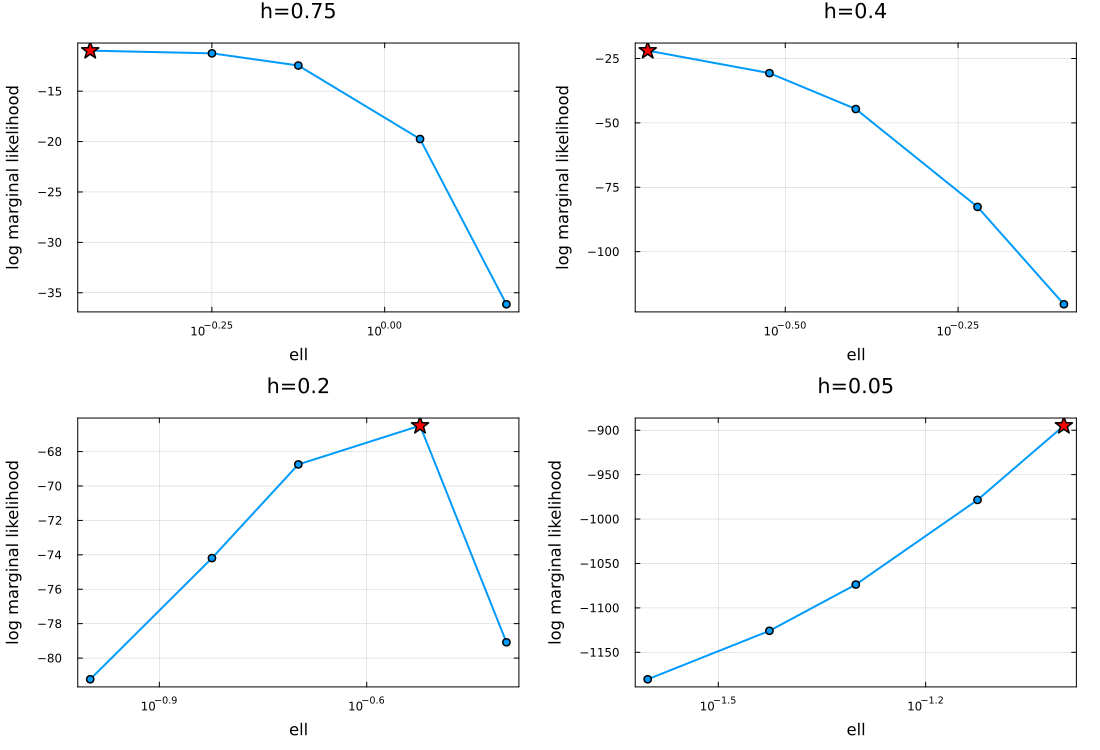

Saved: poisson_proposed_lml_ell_4h.png


In [12]:

# ============================================================
# LML curves for ell
# ============================================================

plots_lml = []

for dt in dt_list

    ell_grid = ell_scores[dt].ell_grid
    scores = ell_scores[dt].scores

    best_ell,
    sigma_f,
    C_hat,
    best_lml =
        best_params[dt]

    p = plot(
        ell_grid,
        scores;
        xscale=:log10,
        marker=:circle,
        lw=2,
        xlabel="ell",
        ylabel="log marginal likelihood",
        title="h=$(dt)",
        label=false,
        framestyle=:box
    )

    scatter!(
        p,
        [best_ell],
        [best_lml];
        marker=:star5,
        markersize=9,
        color=:red,
        label=false
    )

    push!(plots_lml, p)
end

fig_lml = plot(
    plots_lml...;
    layout=(2,2),
    size=(1100,750),
    margin=4*Plots.mm
)

display(fig_lml)

savefig(
    fig_lml,
    "poisson_proposed_lml_ell_4h.png"
)

println("Saved: poisson_proposed_lml_ell_4h.png")


## Fine-test posterior for the four mesh sizes

In [13]:
function run_pfdm(dt; ν, ℓ, σf, C, τ, n_test=1801)
    # --------------------------------------------------------
    # Training grid
    # --------------------------------------------------------
    x_train = collect(0.0:dt:18.0)
    n_train = length(x_train)

    H       = observation_matrix(n_train, dt)
    y_train = make_y_train(x_train)

    noise_var = C * dt^(2τ)
    Σ_diag = vcat(
        [0.0],
        fill(noise_var, n_train - 2),
        [0.0]
    )
    Σ = Diagonal(Σ_diag)

    K_train = kernel_matrix_matern(
        x_train, x_train;
        ν=ν, ℓ=ℓ, σf=σf
    )

    K_obs = Hermitian(
        H * K_train * H' +
        Σ +
        1e-10 * I
    )

    K_chol = cholesky(K_obs)

    # --------------------------------------------------------
    # Fine test grid
    # --------------------------------------------------------
    X_test = collect(
        range(0.0, 18.0, length=n_test)
    )

    K_test_train = kernel_matrix_matern(
        X_test, x_train;
        ν=ν, ℓ=ℓ, σf=σf
    )

    # Cross covariance with observations
    Ks = K_test_train * H'

    # Posterior mean
    μ_post = Ks * (K_chol \ y_train)

    # Posterior variance:
    # k(x*,x*) = σf^2 for stationary Matérn kernel
    W = K_chol.L \ Ks'

    var_post =
        σf^2 .-
        vec(sum(W.^2, dims=1))

    std_post =
        sqrt.(max.(var_post, 0.0))

    u_true =
        u_exact.(X_test)

    return X_test, μ_post, std_post, u_true
end

run_pfdm (generic function with 1 method)


=== Fine test-grid results ===
h        ell        C_hat        RMSE       Linf       coverage   mean CI   
------------------------------------------------------------------------------
0.75     0.375      1.687e-30    0.1606     0.2559     0.768      0.2008    
0.4      0.2        1.844        0.008719   0.0136     1.000      0.04947   
0.2      0.3        4.239        0.001908   0.003663   1.000      0.02379   
0.05     0.1        5.353        0.0001322  0.000395   1.000      0.006777  

Saved: poisson_proposed_posterior_4h.png


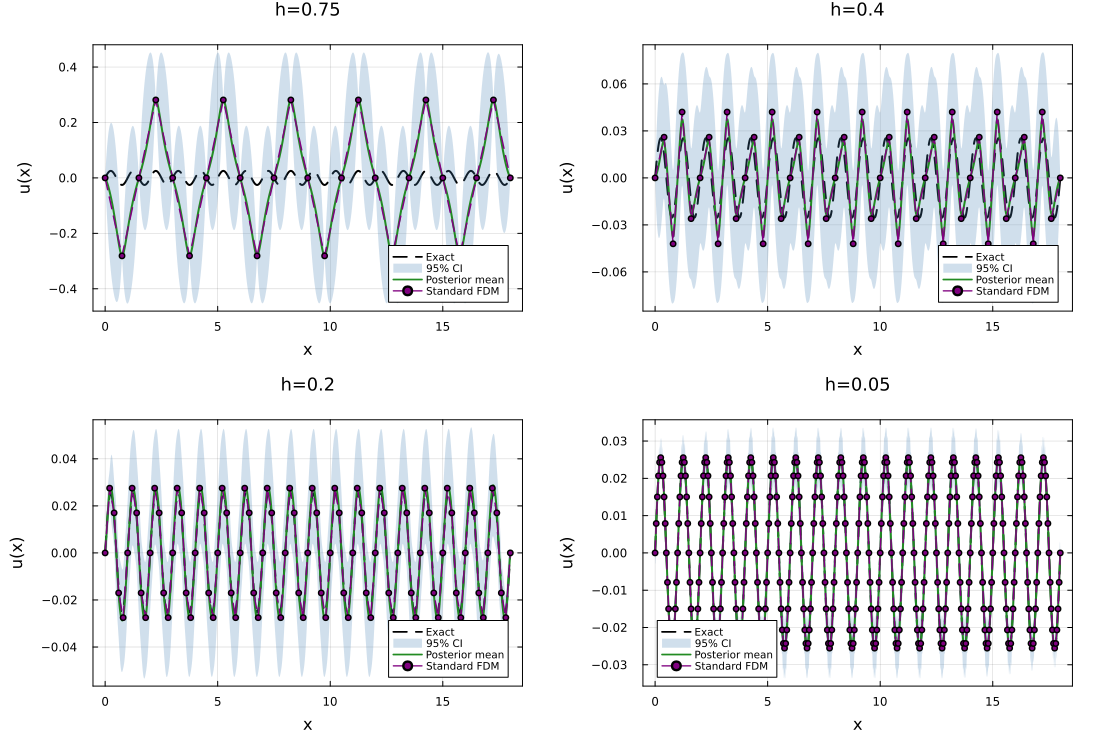

In [14]:

# ============================================================
# Fine-test posterior results for all four h values
# ============================================================

posterior_results = Dict()
plots_post = []

println()
println("=== Fine test-grid results ===")

@printf(
    "%-8s %-10s %-12s %-10s %-10s %-10s %-10s\n",
    "h",
    "ell",
    "C_hat",
    "RMSE",
    "Linf",
    "coverage",
    "mean CI"
)

println("-"^78)

for dt in dt_list

    best_ell,
    sigma_f,
    C_hat,
    best_lml =
        best_params[dt]

    X_test,
    mu,
    std,
    u_true_vals =
        run_pfdm(
            dt;
            ν=ν_fixed,
            ℓ=best_ell,
            σf=sigma_f,
            C=C_hat,
            τ=τ_fixed,
            n_test=1801
        )

    err = mu .- u_true_vals
    abs_err = abs.(err)

    rmse = sqrt(mean(err.^2))
    linf = maximum(abs_err)

    coverage =
        mean(
            abs_err .<=
            1.96 .* std
        )

    mean_ci =
        mean(
            1.96 .* std
        )

    posterior_results[dt] =
        (
            X=X_test,
            mu=mu,
            std=std,
            truth=u_true_vals,
            rmse=rmse,
            linf=linf,
            coverage=coverage,
            mean_ci=mean_ci
        )

    @printf(
        "%-8.3g %-10.3g %-12.4g %-10.4g %-10.4g %-10.3f %-10.4g\n",
        dt,
        best_ell,
        C_hat,
        rmse,
        linf,
        coverage,
        mean_ci
    )

    x_fdm, u_fdm = solve_fdm(dt)

    p = plot(
        X_test,
        u_true_vals;
        label="Exact",
        lw=2,
        ls=:dash,
        color=:black,
        xlabel="x",
        ylabel="u(x)",
        title="h=$(dt)",
        titlefontsize=12,
        legendfontsize=7,
        framestyle=:box
    )

    plot!(
        p,
        X_test,
        mu .+ 1.96 .* std;
        fillrange=mu .- 1.96 .* std,
        fillalpha=0.25,
        linealpha=0,
        label="95% CI",
        color=:steelblue
    )

    plot!(
        p,
        X_test,
        mu;
        label="Posterior mean",
        lw=2,
        color=:forestgreen
    )

    plot!(
        p,
        x_fdm,
        u_fdm;
        label="Standard FDM",
        lw=1.5,
        ls=:dash,
        marker=:circle,
        markersize=3,
        color=:purple
    )

    push!(plots_post, p)
end

fig_post = plot(
    plots_post...;
    layout=(2,2),
    size=(1100,750),
    margin=5*Plots.mm
)

display(fig_post)

savefig(
    fig_post,
    "poisson_proposed_posterior_4h.png"
)

println()
println("Saved: poisson_proposed_posterior_4h.png")
